In [16]:
import glob, os, sys, time, tempfile, subprocess
import numpy as np, pandas as pd
import SimpleITK as sitk
import ants

t1_files = sorted(glob.glob("C:/data/brats/**/*-t1n.nii.gz", recursive=True))
africa = [f for f in t1_files if "BraTS-SSA" in os.path.basename(f) and "95_Glioma" in f]
gli    = [f for f in t1_files if "BraTS-GLI" in os.path.basename(f)]
print(len(africa), "Africa,", len(gli), "GLI")

rng = np.random.default_rng(0)
gli_sample = sorted(rng.choice(gli, size=len(africa), replace=False).tolist())
cases = [("Africa", f) for f in africa] + [("GLI", f) for f in gli_sample]
print(len(cases), "cases in the study")

95 Africa, 1251 GLI
190 cases in the study


In [17]:
def random_warp(img, seed, max_rot_deg=8, max_shift_mm=8, max_bend_mm=5):
    rng = np.random.default_rng(seed)
    center = img.TransformContinuousIndexToPhysicalPoint([(s - 1) / 2 for s in img.GetSize()])

    rigid = sitk.Euler3DTransform()
    rigid.SetCenter(center)
    rigid.SetRotation(*np.deg2rad(rng.uniform(-max_rot_deg, max_rot_deg, 3)))
    rigid.SetTranslation(rng.uniform(-max_shift_mm, max_shift_mm, 3))

    bend = sitk.BSplineTransformInitializer(img, [6, 6, 6], order=3)   # coarse control grid
    p = np.clip(rng.normal(0, max_bend_mm / 2, len(bend.GetParameters())), -max_bend_mm, max_bend_mm)
    bend.SetParameters(p.tolist())

    return sitk.CompositeTransform([rigid, bend])

In [18]:
def sample_points(img, mask, step):
    idx = np.argwhere(mask)[::step][:, ::-1].astype(float)        # (z,y,x) -> (x,y,z)
    return np.array([img.TransformContinuousIndexToPhysicalPoint(p.tolist()) for p in idx])

def errors_mm(predicted, truth_transform, pts):
    truth = np.array([truth_transform.TransformPoint(p) for p in pts])
    return np.linalg.norm(predicted - truth, axis=1)

In [19]:
def run_affine(fixed_path, moving_path):
    fixed = sitk.ReadImage(fixed_path, sitk.sitkFloat32)
    moving = sitk.ReadImage(moving_path, sitk.sitkFloat32)
    R = sitk.ImageRegistrationMethod()
    R.SetMetricAsMattesMutualInformation(50)
    R.SetMetricSamplingStrategy(R.RANDOM); R.SetMetricSamplingPercentage(0.05, seed=0)
    R.SetInterpolator(sitk.sitkLinear)
    R.SetOptimizerAsRegularStepGradientDescent(1.0, 1e-4, 300)
    R.SetOptimizerScalesFromPhysicalShift()
    R.SetShrinkFactorsPerLevel([4, 2, 1]); R.SetSmoothingSigmasPerLevel([2, 1, 0])
    init = sitk.CenteredTransformInitializer(fixed, moving, sitk.AffineTransform(3),
                                             sitk.CenteredTransformInitializerFilter.GEOMETRY)
    R.SetInitialTransform(init, inPlace=False)
    T = R.Execute(fixed, moving)
    return lambda P: np.array([T.TransformPoint(p) for p in P]), {}

def run_ants(fixed_path, moving_path):
    fixed = ants.image_read(fixed_path)
    r = ants.registration(fixed, ants.image_read(moving_path), type_of_transform="SyN")
    jac = ants.create_jacobian_determinant_image(fixed, r["fwdtransforms"][0]).numpy()
    def mapper(P):
        df = pd.DataFrame(P, columns=["x", "y", "z"])
        return ants.apply_transforms_to_points(3, df, r["fwdtransforms"])[["x", "y", "z"]].values
    return mapper, {"fold_pct": float((jac <= 0).mean() * 100)}

def run_unigradicon(fixed_path, moving_path, out_path):
    cmd = [sys.executable, "-c", "import sys; from unigradicon import main; sys.exit(main())",
           "--fixed", fixed_path, "--fixed_modality", "mri",
           "--moving", moving_path, "--moving_modality", "mri",
           "--transform_out", out_path, "--io_iterations", "None"]
    subprocess.run(cmd, check=True, capture_output=True)
    T = sitk.ReadTransform(out_path)
    return lambda P: np.array([T.TransformPoint(p) for p in P]), {}

In [ ]:
img = sitk.ReadImage(cases[0][1], sitk.sitkFloat32)
shift = sitk.TranslationTransform(3, (10.0, 0.0, 0.0))
tmp = tempfile.mkdtemp()
fp, mp = os.path.join(tmp, "fixed.nii.gz"), os.path.join(tmp, "moving.nii.gz")
sitk.WriteImage(sitk.Resample(img, img, shift, sitk.sitkLinear, 0.0, sitk.sitkFloat32), fp)
sitk.WriteImage(img, mp)
fixed = sitk.ReadImage(fp)
P = sample_points(fixed, sitk.GetArrayFromImage(fixed) > 0, step=500)

for name, fn in [("affine", run_affine), ("ANTs", run_ants)]:
    mapper, _ = fn(fp, mp)
    print(name, f"{errors_mm(mapper(P), shift, P).mean():.2f} mm")
mapper, _ = run_unigradicon(fp, mp, os.path.join(tmp, "u.hdf5"))
print("uniGradICON", f"{errors_mm(mapper(P), shift, P).mean():.2f} mm")

In [9]:
def run_case(group, t1_path, seed):
    seg_path = t1_path.replace("-t1n.nii.gz", "-seg.nii.gz")
    img = sitk.ReadImage(t1_path, sitk.sitkFloat32)
    seg = sitk.ReadImage(seg_path)
    truth = random_warp(img, seed)

    fixed = sitk.Resample(img, img, truth, sitk.sitkLinear, 0.0, sitk.sitkFloat32)   # warped copy
    fixed_seg = sitk.Resample(seg, img, truth, sitk.sitkNearestNeighbor, 0)
    brain = sitk.GetArrayFromImage(fixed) > 0
    tumour = sitk.GetArrayFromImage(fixed_seg) > 0
    P_normal = sample_points(fixed, brain & ~tumour, step=500)
    P_tumour = sample_points(fixed, tumour, step=max(1, tumour.sum() // 2000))

    tmp = tempfile.mkdtemp()
    fp, mp = os.path.join(tmp, "fixed.nii.gz"), os.path.join(tmp, "moving.nii.gz")
    sitk.WriteImage(fixed, fp); sitk.WriteImage(img, mp)
    case = os.path.basename(t1_path).replace("-t1n.nii.gz", "")
    start = np.linalg.norm(np.array([truth.TransformPoint(p) for p in P_normal]) - P_normal, axis=1).mean()

    rows, mapped = [], {}
    for method in ["affine", "ANTs SyN", "uniGradICON"]:
        t0 = time.time()
        if method == "affine":     mapper, extra = run_affine(fp, mp)
        elif method == "ANTs SyN": mapper, extra = run_ants(fp, mp)
        else:                      mapper, extra = run_unigradicon(fp, mp, os.path.join(tmp, "u.hdf5"))
        secs = time.time() - t0
        mapped[method] = mapper(P_normal)
        rows.append(dict(case=case, group=group, method=method, seconds=round(secs, 1),
                         start_error_mm=start,
                         normal_mm=errors_mm(mapped[method], truth, P_normal).mean(),
                         normal_p95_mm=np.percentile(errors_mm(mapped[method], truth, P_normal), 95),
                         tumour_mm=errors_mm(mapper(P_tumour), truth, P_tumour).mean() if len(P_tumour) else np.nan,
                         **extra))

    # RegCheck signal 1: how much do the two deformable methods disagree? (needs no ground truth)
    disagree = np.linalg.norm(mapped["ANTs SyN"] - mapped["uniGradICON"], axis=1).mean()
    for r in rows: r["ants_vs_ugi_disagreement_mm"] = disagree

    for f in glob.glob(os.path.join(tmp, "*")): os.remove(f)       # delete the 130 MB file
    return rows

test = pd.DataFrame(run_case(*cases[0], seed=0)); test

,case,group,method,seconds,start_error_mm,normal_mm,normal_p95_mm,tumour_mm,ants_vs_ugi_disagreement_mm,fold_pct
0,BraTS-SSA-00009-000,Africa,affine,3.6,12.909501,1.274863,2.127347,1.119481,1.710195,NaN
1,BraTS-SSA-00009-000,Africa,ANTs SyN,26.5,12.909501,0.763104,1.515438,0.528077,1.710195,0.0
2,BraTS-SSA-00009-000,Africa,uniGradICON,71.9,12.909501,1.877066,5.407018,0.422934,1.710195,NaN


In [ ]:
out_csv = "../results/part1_known_warps.csv"
done = set(pd.read_csv(out_csv).case) if os.path.exists(out_csv) else set()

PILOT = False                       # set to False for the overnight run
todo = [c for c in cases if c[0] == "Africa"][:10] + [c for c in cases if c[0] == "GLI"][:10] if PILOT else cases

for i, (group, path) in enumerate(todo):
    case = os.path.basename(path).replace("-t1n.nii.gz", "")
    if case in done: continue
    try:
        same_group = [c for c in cases if c[0] == group]
        rows = run_case(group, path, seed=same_group.index((group, path)))
    except Exception as e:
        print("FAILED", case, e); continue
    pd.DataFrame(rows).to_csv(out_csv, mode="a", header=not os.path.exists(out_csv), index=False)
    print(i + 1, "/", len(todo), case, "done")

1 / 20 BraTS-SSA-00009-000 done
2 / 20 BraTS-SSA-00018-000 done
3 / 20 BraTS-SSA-00040-000 done
4 / 20 BraTS-SSA-00045-000 done
5 / 20 BraTS-SSA-00062-000 done
6 / 20 BraTS-SSA-00073-000 done
7 / 20 BraTS-SSA-00089-000 done
8 / 20 BraTS-SSA-00091-000 done
9 / 20 BraTS-SSA-00105-000 done
10 / 20 BraTS-SSA-00106-000 done
11 / 20 BraTS-GLI-00005-000 done
12 / 20 BraTS-GLI-00008-001 done
13 / 20 BraTS-GLI-00011-000 done
14 / 20 BraTS-GLI-00019-000 done
15 / 20 BraTS-GLI-00024-000 done
16 / 20 BraTS-GLI-00031-001 done
17 / 20 BraTS-GLI-00036-001 done
18 / 20 BraTS-GLI-00048-001 done
19 / 20 BraTS-GLI-00060-000 done
20 / 20 BraTS-GLI-00061-001 done


In [11]:
df = pd.read_csv(out_csv)

def boot_diff(a, b, n=5000, seed=0):
    r = np.random.default_rng(seed)
    d = [r.choice(a, len(a)).mean() - r.choice(b, len(b)).mean() for _ in range(n)]
    return np.percentile(d, [2.5, 97.5])

summary = []
for method, g in df.groupby("method"):
    af, gl = g[g.group == "Africa"], g[g.group == "GLI"]
    lo, hi = boot_diff(af.normal_mm.values, gl.normal_mm.values)
    summary.append(dict(method=method,
                        GLI_normal_mm=gl.normal_mm.mean(), Africa_normal_mm=af.normal_mm.mean(),
                        diff_CI_low=lo, diff_CI_high=hi,
                        GLI_tumour_mm=gl.tumour_mm.mean(), Africa_tumour_mm=af.tumour_mm.mean()))
summary = pd.DataFrame(summary).round(2); summary

,method,GLI_normal_mm,Africa_normal_mm,diff_CI_low,diff_CI_high,GLI_tumour_mm,Africa_tumour_mm
0,ANTs SyN,0.58,0.57,-0.12,0.11,0.80,0.57
1,affine,1.04,1.05,-0.07,0.10,1.14,1.00
2,uniGradICON,1.37,1.53,-0.20,0.54,1.30,0.74


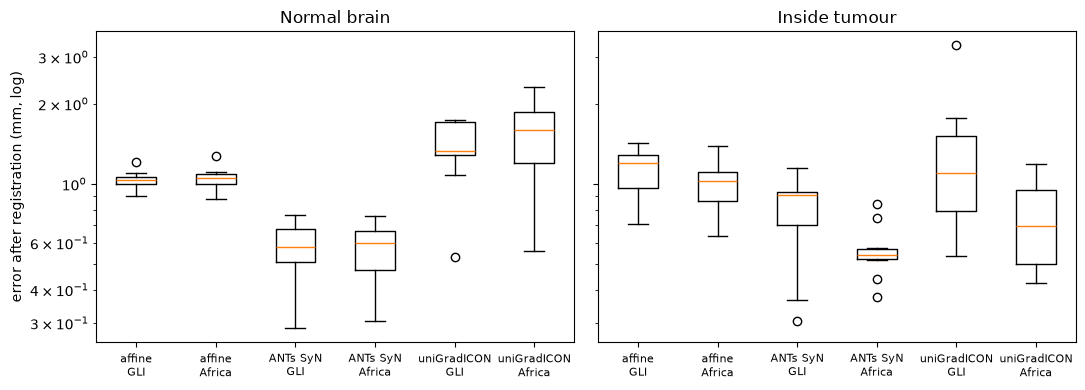

In [12]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, col, title in [(axes[0], "normal_mm", "Normal brain"), (axes[1], "tumour_mm", "Inside tumour")]:
    data, labels = [], []
    for m in ["affine", "ANTs SyN", "uniGradICON"]:
        for grp in ["GLI", "Africa"]:
            data.append(df[(df.method == m) & (df.group == grp)][col].dropna()); labels.append(f"{m}\n{grp}")
    ax.boxplot(data, showfliers=True); ax.set_xticks(range(1, len(labels) + 1), labels, fontsize=8)
    ax.set_title(title); ax.set_yscale("log")
axes[0].set_ylabel("error after registration (mm, log)")
plt.tight_layout(); plt.savefig("../figures/part1_gli_vs_africa.png", dpi=150); plt.show()

In [15]:
from collections import Counter
ids = [os.path.basename(f).replace("-t1n.nii.gz", "") for f in africa]
print(len(ids), "files,", len(set(ids)), "unique cases")
print("duplicated:", [k for k, v in Counter(ids).items() if v > 1][:5])
no_seg = [f for f in africa if not os.path.exists(f.replace("-t1n.nii.gz", "-seg.nii.gz"))]
print(len(no_seg), "Africa cases without a -seg file")
print(sorted(set(os.path.dirname(os.path.dirname(f)) for f in africa)))

146 files, 146 unique cases
duplicated: []
0 Africa cases without a -seg file
['C:/data/brats\\BraTS-Africa\\51_OtherNeoplasms', 'C:/data/brats\\BraTS-Africa\\95_Glioma']


In [14]:
out_csv = "../results/part1_known_warps.csv"
done = set(pd.read_csv(out_csv).case) if os.path.exists(out_csv) else set()

PILOT = True                       # set to False for the overnight run
todo = [c for c in cases if c[0] == "Africa"][:10] + [c for c in cases if c[0] == "GLI"][:10] if PILOT else cases

for i, (group, path) in enumerate(todo):
    case = os.path.basename(path).replace("-t1n.nii.gz", "")
    if case in done: continue
    try:
        same_group = [c for c in cases if c[0] == group]
        rows = run_case(group, path, seed=same_group.index((group, path)))
    except Exception as e:
        print("FAILED", case, e); continue
    pd.DataFrame(rows).to_csv(out_csv, mode="a", header=not os.path.exists(out_csv), index=False)
    print(i + 1, "/", len(todo), case, "done")